<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/04_juncao_e_destaques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/04_juncao_e_destaques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resultado final, notebook 04: junção das fontes e cidades em destaque

**Objetivo:** juntar, para cada município do RN, todo o dinheiro que chegou de fora entre 2020 e 2023 (repasses
obrigatórios do Estado, convênios e emendas parlamentares federais), **sem contar nada duas vezes e sem perder nada**, e
ver se as cidades em destaque continuam as mesmas quando olhamos o total.

| Fonte | Notebook | O que entra |
|---|---|---|
| Repasses obrigatórios (ICMS, IPVA, IPI-Exportação, royalties) | 01 | Valor recebido em cada ano |
| Convênios federais e estaduais | 02 | Convênios iniciados em 2020–2023, com o valor liberado (federal) ou combinado (estadual) |
| Emendas federais **sem convênio** (Pix e outros pagamentos diretos) | 03 | Valor recebido em cada ano |
| Emendas pagas em 2020–2023 em **convênios iniciados antes de 2020** | 03 + 02 (seção 2) | Valor recebido em cada ano |

**Fica de fora**, como combinado no grupo: a emenda de saúde fundo a fundo, porque de 2020 a 2023 o Portal da
Transparência não informa qual município a recebeu (ver notebook 03, seção 5.3).

**Arquivos gerados (pasta `resultado_final/saida/`):**

| Arquivo | Conteúdo |
|---|---|
| `04_base_unificada_2020_2023.csv` | Uma linha por município: cada fonte, o total, os valores por habitante, as posições e a marcação de destaque |
| `04_base_unificada_municipio_ano.csv` | Uma linha por município, ano e fonte |
| `04_cidades_destaque.csv` | As cidades em destaque, com o motivo de cada uma. Vai para o notebook 05 (cidades gêmeas) |

## 1. Bibliotecas, funções e bases dos notebooks 01 a 03

In [1]:
import os
import re
import time
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

RAW_GITHUB = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/'
ANOS = [2020, 2021, 2022, 2023]
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')
pd.set_option('display.max_colwidth', 70)

AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
ROXO, CINZA, CINZA_CLARO = '#7d55c7', '#a3a29b', '#d6d5d0'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'legend.frameon': True,
})

def reais(x, _=None):
    """Formata em reais: 1500 -> 'R$ 1,5 mil' | 2_300_000 -> 'R$ 2,3 mi'."""
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if abs(x) >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.2f}'.rstrip('0').rstrip('.').replace('.', ',')
            return f'R$ {texto}{sufixo}'
    return f'R$ {x:.0f}'

def virgula(x, casas=1):
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

FORMATO_REAIS = mticker.FuncFormatter(reais)

def ler_csv(caminho, tentativas=3, **kwargs):
    """Lê do GitHub do projeto (tenta de novo se a conexão cair); se não conseguir, lê a cópia local (mesmo caminho)."""
    for _ in range(tentativas):
        try:
            return pd.read_csv(RAW_GITHUB + caminho, **kwargs)
        except Exception as e:
            erro = e
            if '404' in str(e):
                break
            time.sleep(3)
    if os.path.exists(caminho):
        return pd.read_csv(caminho, **kwargs)
    if '404' in str(erro):
        raise FileNotFoundError(
            f'O arquivo "{caminho}" não está no GitHub do projeto. '
            f'Suba-o para a pasta {os.path.dirname(caminho)}/ do repositório, com o mesmo nome, '
            'e rode a célula de novo.') from None
    raise ConnectionError(
        f'Não consegui baixar "{caminho}" do GitHub: o ambiente parece estar sem internet. '
        f'Erro original: {erro}') from None

def chave(nome):
    """Nome sem acento, pontuação e caixa: 'Olho-d'Água do Borges' -> 'OLHO DAGUA DO BORGES'."""
    texto = unicodedata.normalize('NFKD', str(nome)).encode('ascii', 'ignore').decode().upper().replace('-', ' ')
    return re.sub(r'\s+', ' ', re.sub(r'[^A-Z ]', '', texto)).strip()

def moeda(coluna):
    """'1.234,56' -> 1234.56"""
    return pd.to_numeric(coluna.astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
                         errors='coerce')

os.makedirs('resultado_final/saida', exist_ok=True)

# Cidades em destaque do notebook 06 (só repasses). A lista nova sai da seção 4 deste notebook.
DESTAQUE_06 = ['Guamaré', 'São Bento do Norte', 'Pedra Grande', 'Parazinho', 'Galinhos', 'Bodó', 'Serra do Mel']

In [2]:
rep = ler_csv('resultado_final/saida/01_repasses_municipios_2020_2023.csv')
rep_ano = ler_csv('resultado_final/saida/01_repasses_municipio_ano.csv')
base01 = ler_csv('resultado_final/saida/01_base_municipios_2020_2023.csv')
conv = ler_csv('resultado_final/saida/02_convenios_municipios_2020_2023.csv')
conv_ano = ler_csv('resultado_final/saida/02_convenios_municipio_ano.csv')
eme = ler_csv('resultado_final/saida/03_emendas_municipios_2020_2023.csv')
eme_ano = ler_csv('resultado_final/saida/03_emendas_municipio_ano.csv')
for nome, t in [('01', rep), ('02', conv), ('03', eme)]:
    assert len(t) == 167 and t['cod_ibge'].is_unique, f'base {nome} sem os 167 municípios'

FATOR_IPCA = base01.drop_duplicates('ano').set_index('ano')['fator_ipca']
municipios = rep[['cod_ibge', 'municipio']].copy()
municipios['chave'] = municipios['municipio'].map(chave)
NOMES_ANTIGOS = {'ACU': 'ASSU', 'ARES': 'AREZ', 'AUGUSTO SEVERO': 'CAMPO GRANDE', 'PRESIDENTE JUSCELINO': 'SERRA CAIADA',
                 'BOA SAUDE': 'JANUARIO CICCO', 'OLHO DAGUA DOS BORGES': 'OLHO DAGUA DO BORGES'}

def para_cod_ibge(nomes):
    return nomes.map(chave).replace(NOMES_ANTIGOS).map(municipios.set_index('chave')['cod_ibge'])

print('Totais de 2020 a 2023 (R$ de 2023): repasses', reais(rep['rep_total_valor'].sum()),
      '| convênios', reais(conv['total_valor'].sum()), '| emendas', reais(eme['total_valor'].sum()))

Totais de 2020 a 2023 (R$ de 2023): repasses R$ 8,84 bi | convênios R$ 938 mi | emendas R$ 844 mi


## 2. Conciliação entre convênios (02) e emendas (03)

Os dois notebooks contam o tempo de jeitos diferentes:

- o **02** conta cada convênio no **ano em que ele começou**, com tudo o que foi liberado até hoje;
- o **03** conta cada pagamento de emenda no **ano em que o dinheiro chegou**.

Uma emenda paga por convênio pode cair em três situações:

| Situação | Exemplo | O que fazemos |
|---|---|---|
| O convênio começou em 2020–2023 | Emenda paga em 2021 num convênio de 2020 | Já está no 02: **não soma de novo** |
| O convênio começou **antes de 2020** | Emenda paga em 2021 num convênio de 2018 | Não está no 02 (fora do recorte) nem no total sem convênio do 03: **recuperamos** |
| A emenda não tem convênio | Pix, pagamentos diretos | Está no 03 (`sem_convenio_valor`): **soma direto** |

Para separar as duas primeiras, ligamos cada pagamento de emenda ao **número do convênio** (arquivo de convênios do
Portal) e olhamos o **ano de início** desse convênio no arquivo do 02. Os passos de leitura e limpeza são os mesmos dos
notebooks 02 e 03.

In [3]:
# Convênios federais das prefeituras, com a mesma limpeza do notebook 02
fed = ler_csv('dados/emendas/convenio.csv', sep=';', dtype=str)
fed = fed.loc[:, ~fed.columns.str.startswith('Unnamed')]
fed.columns = ['numero', 'uf', 'municipio_portal', 'situacao', 'tipo_instrumento', 'objeto', 'orgao_superior',
               'orgao_vinculado', 'concedente', 'convenente', 'inicio_vigencia', 'fim_vigencia', 'publicacao',
               'valor_liberado', 'valor_celebrado']
fed['numero'] = fed['numero'].str.strip()
fed['ano'] = pd.to_datetime(fed['inicio_vigencia'], format='%d/%m/%Y', errors='coerce').dt.year
fed = fed[fed['convenente'].str.upper().str.strip().str.startswith('MUNICIPIO DE')
          & ~fed['situacao'].str.upper().isin(['CONVÊNIO ANULADO', 'EXCLUÍDO', 'CANCELADO', 'RESCINDIDO'])
          & fed['ano'].between(2004, 2025)]
ANO_INICIO = fed.set_index('numero')['ano'].to_dict()
fed_recorte = fed[fed['ano'].isin(ANOS)].copy()
fed_recorte['cod_ibge'] = para_cod_ibge(fed_recorte['municipio_portal'])
fed_recorte['liberado_real'] = moeda(fed_recorte['valor_liberado']) * fed_recorte['ano'].map(FATOR_IPCA)
assert abs(fed_recorte['liberado_real'].sum() - conv['fed_valor'].sum()) < 1, 'limpeza diferente da do notebook 02'

# Pagamentos de emendas às prefeituras, com a mesma classificação do notebook 03
pag = ler_csv('dados/emendas/emendas_por_favorecido_rn.csv', dtype=str)
pag = pag[pag['Natureza Jurídica'].isin(['Município', 'Fundo Público da Administração Direta Municipal'])].copy()
pag['valor'] = moeda(pag['Valor Recebido'])
pag['ano'] = pag['Ano/Mês'].str[:4].astype(int)
pag['cod_ibge'] = para_cod_ibge(pag['Município Favorecido'])
pag = pag[pag['ano'].isin(ANOS)].copy()
pag['valor_real'] = pag['valor'] * pag['ano'].map(FATOR_IPCA)

ligacao = ler_csv('dados/emendas/emendas_convenios_rn_portal.csv', dtype=str)
ligacao = ligacao[ligacao['Localidade do gasto'].str.endswith('- RN')
                  & ligacao['Convenente'].str.upper().str.startswith('MUNICIPIO')].copy()
ligacao['cod_ibge'] = para_cod_ibge(ligacao['Localidade do gasto'].str.replace(' - RN', '', regex=False))
ligacao['numero'] = ligacao['Número Convênio'].str.strip()
CONVENIOS_DA_EMENDA = ligacao.groupby(['Código da Emenda', 'cod_ibge'])['numero'].apply(set).to_dict()

pag['convenios'] = [CONVENIOS_DA_EMENDA.get((e, c), set()) for e, c in zip(pag['Código da Emenda'], pag['cod_ibge'])]
pag['pix'] = pag['Tipo de Emenda'].str.contains('Especiais')

def situacao(linha):
    if linha['pix']:
        return 'Pix'
    if not linha['convenios']:
        return 'Outras, sem convênio'
    anos = sorted(ANO_INICIO[n] for n in linha['convenios'] if n in ANO_INICIO)
    if not anos:
        return 'Convênio que não está no 02'
    if any(a in ANOS for a in anos):
        return 'Convênio iniciado em 2020–2023 (já no 02)'
    return 'Convênio iniciado antes de 2020' if anos[0] < 2020 else 'Convênio iniciado depois de 2023'

pag['situacao'] = pag.apply(situacao, axis=1)

# Conferência: a classificação bate com o notebook 03
via_convenio = pag[~pag['situacao'].isin(['Pix', 'Outras, sem convênio'])]
assert abs(via_convenio['valor_real'].sum() - eme['convenio_valor'].sum()) < 1, 'classificação diferente da do 03'
assert abs(pag.loc[pag['situacao'].isin(['Pix', 'Outras, sem convênio']), 'valor_real'].sum()
           - eme['sem_convenio_valor'].sum()) < 1

conciliacao = (pag.groupby('situacao')['valor_real'].agg(['size', 'sum'])
               .rename(columns={'size': 'Pagamentos', 'sum': 'Valor (R$ de 2023)'}))
conciliacao['O que fazemos'] = conciliacao.index.map({
    'Pix': 'Soma (está no 03)', 'Outras, sem convênio': 'Soma (está no 03)',
    'Convênio iniciado em 2020–2023 (já no 02)': 'Não soma (já está no 02)',
    'Convênio iniciado antes de 2020': 'Recupera e soma',
    'Convênio iniciado depois de 2023': 'Recupera e soma',
    'Convênio que não está no 02': 'Recupera e soma'})
conciliacao['Valor (R$ de 2023)'] = conciliacao['Valor (R$ de 2023)'].map(reais)
conciliacao

,Pagamentos,Valor (R$ de 2023),O que fazemos
situacao,,,
Convênio iniciado antes de 2020,1293,R$ 295 mi,Recupera e soma
Convênio iniciado em 2020–2023 (já no 02),460,R$ 226 mi,Não soma (já está no 02)
"Outras, sem convênio",546,R$ 44 mi,Soma (está no 03)
Pix,704,R$ 279 mi,Soma (está no 03)


**Leitura:** sem essa conciliação, os pagamentos de emenda feitos em 2020–2023 em convênios antigos ficariam fora da
conta, porque o 02 só olha convênios iniciados no período e o 03 os separa como "convênio". É dinheiro que chegou às
prefeituras no período e por isso entra no total como **emendas em convênios anteriores a 2020**.

Também conferimos a categoria "Outras, sem convênio": se alguma dessas emendas aparece no arquivo de convênios do Portal
para **qualquer** convenente, ela poderia ser um convênio que o 02 já conta.

In [4]:
emendas_com_convenio = set(ligacao['Código da Emenda'])
outras = pag[pag['situacao'] == 'Outras, sem convênio']
suspeitas = outras[outras['Código da Emenda'].isin(emendas_com_convenio)]
print(f'"Outras, sem convênio": {reais(outras["valor_real"].sum())} em {len(outras)} pagamentos. '
      f'Desses, {len(suspeitas)} pagamentos ({reais(suspeitas["valor_real"].sum())}) são de emendas que têm convênio '
      f'com outra prefeitura ou entidade.')
print('Como o convênio dessas emendas é com outro convenente, o pagamento à prefeitura não está no convênio dela no 02: '
      'não há contagem dupla.')

"Outras, sem convênio": R$ 44 mi em 546 pagamentos. Desses, 161 pagamentos (R$ 11 mi) são de emendas que têm convênio com outra prefeitura ou entidade.
Como o convênio dessas emendas é com outro convenente, o pagamento à prefeitura não está no convênio dela no 02: não há contagem dupla.


## 3. Base unificada

**Total de cada município (2020–2023, R\$ de 2023)** = repasses + convênios + emendas sem convênio + emendas em
convênios anteriores a 2020.

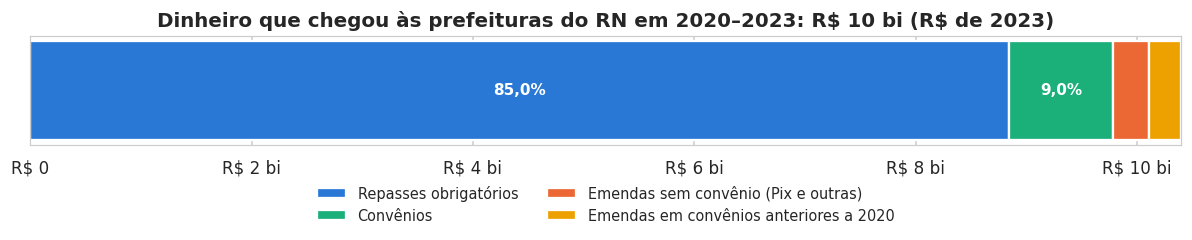

,Valor 2020–2023,% do total,Por habitante por ano
Repasses obrigatórios,"R$ 8,84 bi",85.0,669.3
Convênios,R$ 938 mi,9.0,71.0
Emendas sem convênio (Pix e outras),R$ 323 mi,3.1,24.5
Emendas em convênios anteriores a 2020,R$ 295 mi,2.8,22.4


In [5]:
recuperado = (pag[pag['situacao'].str.startswith('Convênio iniciado antes') | pag['situacao'].str.endswith('depois de 2023')
                  | (pag['situacao'] == 'Convênio que não está no 02')]
              .groupby('cod_ibge')['valor_real'].sum().rename('emendas_conv_anterior_valor'))

FONTES = [('rep_valor', 'Repasses obrigatórios', AZUL),
          ('conv_valor', 'Convênios', VERDE),
          ('emendas_sem_conv_valor', 'Emendas sem convênio (Pix e outras)', LARANJA),
          ('emendas_conv_anterior_valor', 'Emendas em convênios anteriores a 2020', AMARELO)]

uni = (rep[['cod_ibge', 'municipio', 'mesorregiao', 'regiao_intermediaria', 'populacao', 'porte', 'pib_per_capita',
            'pct_baixa_renda', 'rep_total_valor']].rename(columns={'rep_total_valor': 'rep_valor'})
       .merge(conv[['cod_ibge', 'total_valor']].rename(columns={'total_valor': 'conv_valor'}), on='cod_ibge')
       .merge(eme[['cod_ibge', 'sem_convenio_valor']].rename(columns={'sem_convenio_valor': 'emendas_sem_conv_valor'}),
              on='cod_ibge')
       .merge(recuperado, on='cod_ibge', how='left').fillna({'emendas_conv_anterior_valor': 0}))
uni['total_valor'] = uni[[c for c, _, _ in FONTES]].sum(axis=1)
for col, _, _ in FONTES + [('total_valor', '', '')]:
    uni[col.replace('_valor', '_pc_ano')] = uni[col] / uni['populacao'] / len(ANOS)
for col, _, _ in FONTES:
    uni[col.replace('_valor', '_pct')] = uni[col] / uni['total_valor'] * 100
uni['posicao_repasses'] = uni['rep_pc_ano'].rank(ascending=False, method='min').astype(int)
uni['posicao_total'] = uni['total_pc_ano'].rank(ascending=False, method='min').astype(int)

total_geral = uni['total_valor'].sum()
assert abs(total_geral - (rep['rep_total_valor'].sum() + conv['total_valor'].sum() + eme['sem_convenio_valor'].sum()
                          + recuperado.sum())) < 1

composicao = pd.Series({nome: uni[col].sum() for col, nome, _ in FONTES})
fig, ax = plt.subplots(figsize=(11, 2.6))
esquerda = 0
for (col, nome, cor), v in zip(FONTES, composicao):
    ax.barh(0, v, left=esquerda, color=cor, height=0.55, edgecolor='white', linewidth=1.5, label=nome)
    if v / total_geral > 0.04:
        ax.text(esquerda + v / 2, 0, f'{virgula(v / total_geral * 100)}%', ha='center', va='center', color='white',
                fontsize=10, fontweight='bold')
    esquerda += v
ax.set_yticks([])
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, total_geral)
# No matplotlib, dois "$" no mesmo texto viram fórmula; o "\$" mostra o cifrão normal
ax.set_title(f'Dinheiro que chegou às prefeituras do RN em 2020–2023: {reais(total_geral)} (R$ de 2023)'.replace('$', r'\$'))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False, fontsize=9.5)
plt.tight_layout()
plt.show()

(composicao.to_frame('Valor 2020–2023').assign(**{'% do total': composicao / total_geral * 100,
                                                    'Por habitante por ano': composicao / uni['populacao'].sum() / 4})
 .assign(**{'Valor 2020–2023': lambda d: d['Valor 2020–2023'].map(reais)}).round(1))

### 3.1 Ano a ano

Repasses e emendas contam no ano em que o dinheiro chegou; convênios, no ano em que o convênio começou (o valor
liberado de um convênio de 2023 ainda pode ter sido pago em 2024).

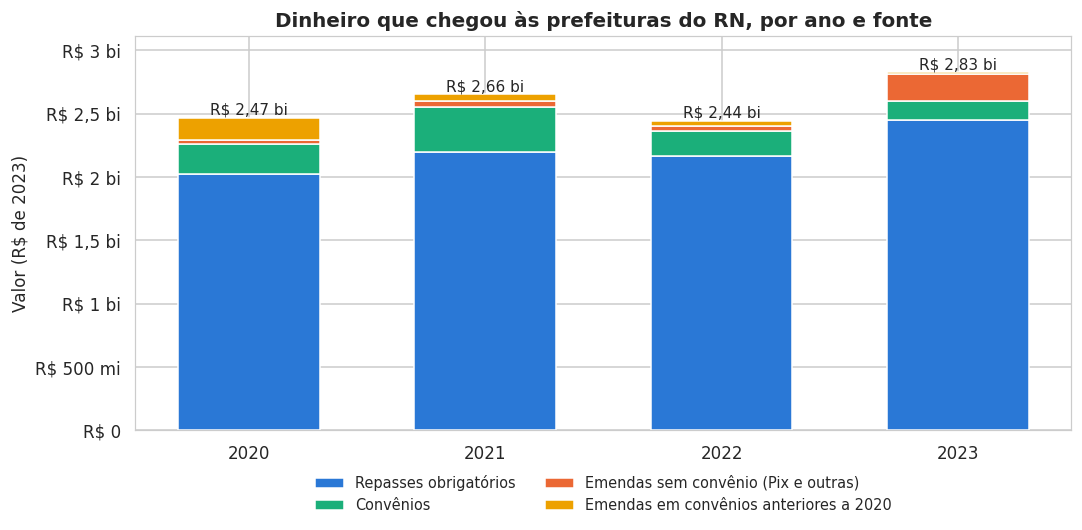

fonte,Repasses obrigatórios,Convênios,Emendas sem convênio (Pix e outras),Emendas em convênios anteriores a 2020,Total
ano,,,,,
2020,"2,022.8",239.4,27.3,179.3,"2,468.8"
2021,"2,201.0",349.5,49.4,55.7,"2,655.6"
2022,"2,165.3",198.6,36.6,43.6,"2,444.1"
2023,"2,453.2",150.6,210.0,16.7,"2,830.5"


In [6]:
rep_ano['fonte'] = 'Repasses obrigatórios'
conv_ano_rec = conv_ano[conv_ano['ano'].isin(ANOS)].assign(fonte='Convênios', valor_real=lambda d: d['valor_liberado_real'])
eme_ano_rec = (eme_ano[eme_ano['ano'].isin(ANOS) & (eme_ano['modalidade'] != 'Convênio')]
               .assign(fonte='Emendas sem convênio (Pix e outras)'))
rec_ano = (pag[pag['situacao'].str.startswith('Convênio iniciado antes') | pag['situacao'].str.endswith('depois de 2023')
               | (pag['situacao'] == 'Convênio que não está no 02')]
           .groupby(['cod_ibge', 'ano'])['valor_real'].sum().reset_index()
           .assign(fonte='Emendas em convênios anteriores a 2020'))
longo = pd.concat([t.groupby(['cod_ibge', 'ano', 'fonte'])['valor_real'].sum().reset_index()
                   for t in [rep_ano, conv_ano_rec, eme_ano_rec, rec_ano]], ignore_index=True)
longo = longo.merge(uni[['cod_ibge', 'municipio', 'populacao']], on='cod_ibge')
longo['valor_pc'] = longo['valor_real'] / longo['populacao']
assert abs(longo['valor_real'].sum() - total_geral) < 1, 'a base ano a ano não fecha com a base 2020–2023'

por_ano = longo.pivot_table(index='ano', columns='fonte', values='valor_real', aggfunc='sum')[[n for _, n, _ in FONTES]]
fig, ax = plt.subplots(figsize=(10, 5))
fundo = np.zeros(len(por_ano))
for _, nome, cor in FONTES:
    ax.bar(por_ano.index, por_ano[nome], bottom=fundo, color=cor, label=nome, width=0.6, edgecolor='white', linewidth=1)
    fundo += por_ano[nome].values
for x, total in zip(por_ano.index, fundo):
    ax.text(x, total, reais(total), ha='center', va='bottom', fontsize=10)
ax.yaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xticks(por_ano.index)
ax.set_ylim(0, fundo.max() * 1.1)
ax.set_ylabel('Valor (R$ de 2023)')
ax.set_title('Dinheiro que chegou às prefeituras do RN, por ano e fonte')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False, fontsize=9.5)
plt.tight_layout()
plt.show()
(por_ano / 1e6).assign(Total=lambda d: d.sum(axis=1)).round(1)

## 4. Cidades em destaque

**Critério (o mesmo do notebook 06):** regra do boxplot aplicada ao **logaritmo** do valor por habitante. Uma cidade é
destaque quando passa de Q3 + 1,5 × (Q3 − Q1), com os quartis calculados na escala log.

**Por que em log:** em dinheiro público o que importa é a proporção (receber o dobro ou dez vezes mais que as
parecidas), e não a diferença em reais. Na escala comum, poucas cidades com valores enormes esticam a régua e o limite
fica baixo, misturando cidades "um pouco acima" com as realmente fora do padrão. Em log, a distância de R\$ 400 para
R\$ 800 (o dobro) vale o mesmo que de R\$ 4.000 para R\$ 8.000.

In [7]:
def limite_log(serie):
    """Limite superior do boxplot calculado em log; devolve o limite já em reais."""
    log = np.log10(serie)
    q1, q3 = log.quantile([0.25, 0.75])
    return 10 ** (q3 + 1.5 * (q3 - q1))

LIMITE_TOTAL = limite_log(uni['total_pc_ano'])
LIMITE_REP = limite_log(uni['rep_pc_ano'])
uni['destaque'] = uni['total_pc_ano'] > LIMITE_TOTAL
uni['destaque_so_repasses'] = uni['rep_pc_ano'] > LIMITE_REP
mediana_total = uni['total_pc_ano'].median()
uni['vezes_mediana'] = uni['total_pc_ano'] / mediana_total

print(f'Limite com todas as fontes: R$ {virgula(LIMITE_TOTAL, 0)} por habitante por ano '
      f'({virgula(LIMITE_TOTAL / mediana_total)} vezes a mediana de R$ {virgula(mediana_total, 0)})')
print(f'Limite só com repasses:     R$ {virgula(LIMITE_REP, 0)} por habitante por ano')
print(f'Cidades em destaque com todas as fontes: {uni["destaque"].sum()} | só com repasses: {uni["destaque_so_repasses"].sum()}')

# Ano a ano: em quantos dos 4 anos a cidade ficou acima do limite (a mesma checagem do notebook 06)
pc_ano = longo.pivot_table(index='cod_ibge', columns='ano', values='valor_pc', aggfunc='sum').reindex(uni['cod_ibge'])
acima_por_ano = pc_ano.apply(lambda col: col > limite_log(col))
uni['anos_acima'] = uni['cod_ibge'].map(acima_por_ano.sum(axis=1)).astype(int)

perto = uni[(uni['total_pc_ano'] > LIMITE_TOTAL * 0.7)].sort_values('total_pc_ano', ascending=False)
(perto.set_index('municipio')[['populacao', 'rep_pc_ano', 'total_pc_ano', 'vezes_mediana', 'anos_acima', 'destaque',
                               'destaque_so_repasses']]
 .rename(columns={'populacao': 'População', 'rep_pc_ano': 'Repasses (R$/hab/ano)', 'total_pc_ano': 'Total (R$/hab/ano)',
                  'vezes_mediana': 'Vezes a mediana', 'anos_acima': 'Anos acima do limite (de 4)',
                  'destaque': 'Destaque (total)', 'destaque_so_repasses': 'Destaque (só repasses)'}))

Limite com todas as fontes: R$ 2.398 por habitante por ano (3,2 vezes a mediana de R$ 741)
Limite só com repasses:     R$ 1.990 por habitante por ano
Cidades em destaque com todas as fontes: 6 | só com repasses: 7


,População,Repasses (R$/hab/ano),Total (R$/hab/ano),Vezes a mediana,Anos acima do limite (de 4),Destaque (total),Destaque (só repasses)
municipio,,,,,,,
Guamaré,15295,"13,325.2","13,330.3",18.0,4,True,True
Galinhos,2104,"4,521.6","5,603.6",7.6,4,True,True
Parazinho,4801,"4,864.2","5,258.0",7.1,4,True,True
São Bento do Norte,3304,"4,761.2","4,952.7",6.7,4,True,True
Pedra Grande,3618,"4,248.6","4,938.5",6.7,4,True,True
Bodó,2306,"4,030.9","4,211.0",5.7,4,True,True
Serra do Mel,13091,"2,037.8","2,247.3",3.0,1,False,True
Riacho da Cruz,2701,848.9,"1,955.8",2.6,0,False,False
Jardim de Angicos,2437,"1,741.2","1,945.0",2.6,0,False,False


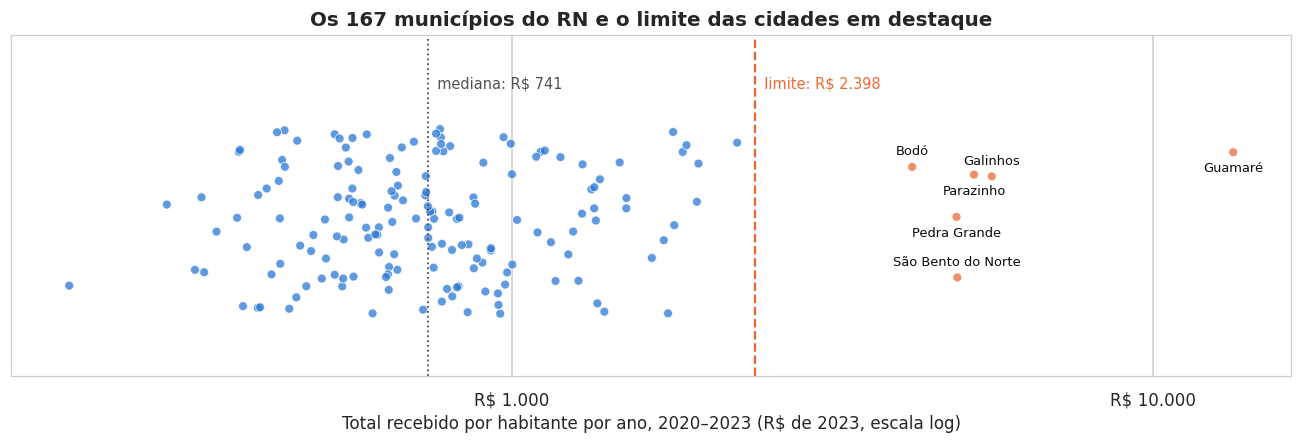

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.2))
rng = np.random.default_rng(7)
jitter = rng.uniform(-0.3, 0.3, len(uni))
cores_pts = np.where(uni['destaque'], LARANJA, AZUL)
ax.scatter(uni['total_pc_ano'], jitter, s=34, c=cores_pts, alpha=0.75, edgecolor='white', linewidth=0.6)
ax.axvline(LIMITE_TOTAL, color=LARANJA, linestyle='--', linewidth=1.5)
ax.text(LIMITE_TOTAL, 0.42, f'  limite: R$ {virgula(LIMITE_TOTAL, 0)}', color=LARANJA, fontsize=9.5, va='bottom')
ax.axvline(mediana_total, color=TEXTO_2, linestyle=':', linewidth=1.2)
ax.text(mediana_total, 0.42, f'  mediana: R$ {virgula(mediana_total, 0)}', color=TEXTO_2, fontsize=9.5, va='bottom')
for i, (_, linha) in enumerate(uni[uni['destaque']].sort_values('total_pc_ano').iterrows()):
    j = jitter[uni.index.get_loc(linha.name)]
    ax.annotate(linha['municipio'], (linha['total_pc_ano'], j), xytext=(0, 8 if i % 2 == 0 else -13),
                textcoords='offset points', fontsize=8.5, ha='center', color=TEXTO)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'R$ {v:,.0f}'.replace(',', '.')))
ax.set_yticks([])
ax.set_ylim(-0.5, 0.6)
ax.set_xlabel('Total recebido por habitante por ano, 2020–2023 (R$ de 2023, escala log)')
ax.set_title('Os 167 municípios do RN e o limite das cidades em destaque')
plt.tight_layout()
plt.show()

### 4.1 O ranking mudou?

O gráfico liga a posição de cada município **só com repasses** (esquerda) à posição **com todas as fontes** (direita),
para as 25 primeiras posições de cada lado. Linhas retas: a posição não mudou. Linhas que sobem: o município subiu ao
somar convênios e emendas.

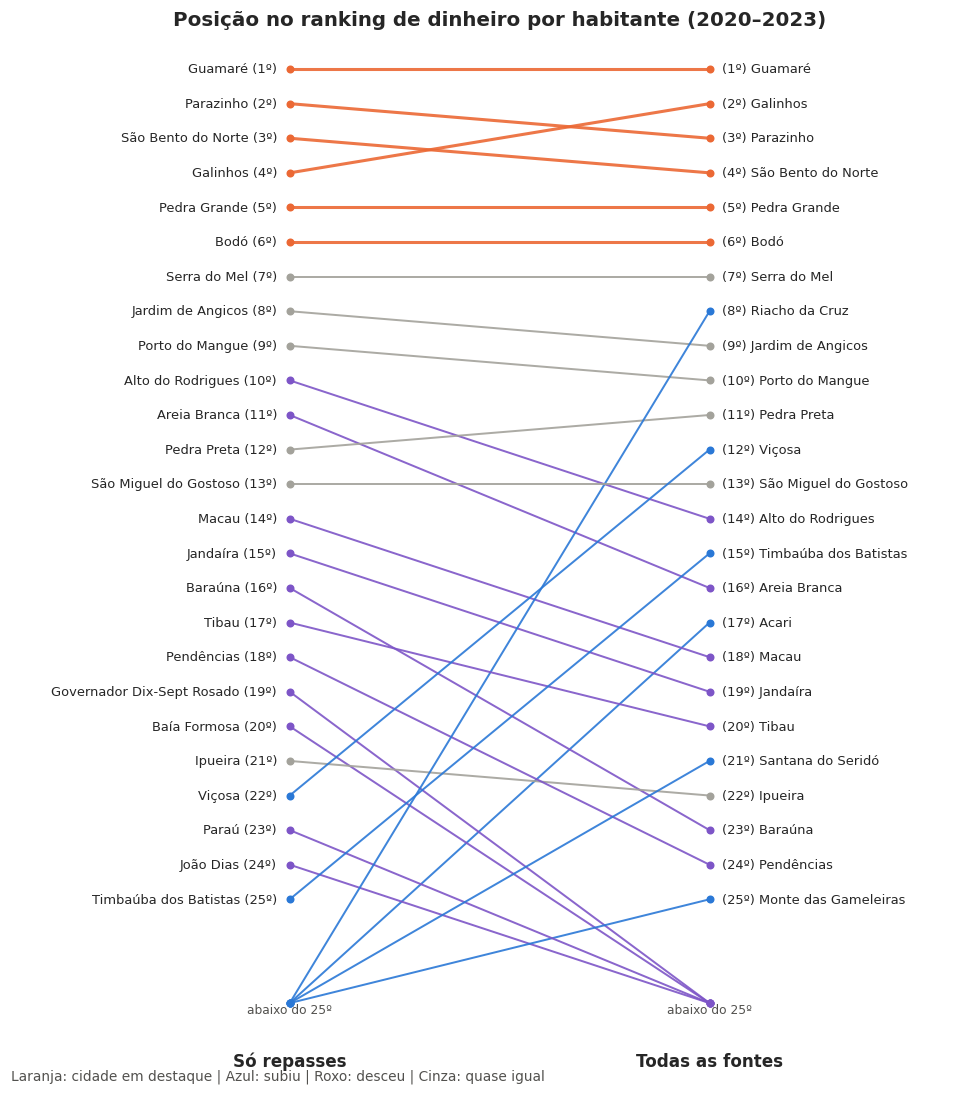

Correlação entre os dois rankings (Spearman): 0,94
Entraram na lista de destaque: nenhuma | Saíram: ['Serra do Mel']


,Posição só repasses,Posição total,Posições que subiu,% do total que vem de repasses,População
municipio,,,,,
Acari,105,17,88,30.5,10597
Maxaranguape,150,82,68,43.5,10255
Itajá,97,34,63,42.6,7292
Portalegre,137,96,41,56.3,7601
Almino Afonso,74,36,38,51.2,4687
Cruzeta,96,59,37,58.2,8005
Doutor Severiano,129,94,35,59.1,7044
Martins,123,91,32,60.0,8179


In [9]:
corte = 25
mostrar = uni[(uni['posicao_repasses'] <= corte) | (uni['posicao_total'] <= corte)]
fig, ax = plt.subplots(figsize=(9, 10))
for _, linha in mostrar.iterrows():
    y0, y1 = min(linha['posicao_repasses'], corte + 3), min(linha['posicao_total'], corte + 3)
    cor = LARANJA if linha['destaque'] else (AZUL if y1 < y0 - 2 else (CINZA if abs(y1 - y0) <= 2 else ROXO))
    ax.plot([0, 1], [y0, y1], color=cor, linewidth=2 if linha['destaque'] else 1.3, alpha=0.9)
    ax.scatter([0, 1], [y0, y1], color=cor, s=18, zorder=3)
    if linha['posicao_repasses'] <= corte:
        ax.text(-0.03, y0, f'{linha["municipio"]} ({linha["posicao_repasses"]}º)', ha='right', va='center', fontsize=8.5)
    if linha['posicao_total'] <= corte:
        ax.text(1.03, y1, f'({linha["posicao_total"]}º) {linha["municipio"]}', ha='left', va='center', fontsize=8.5)
ax.text(0, corte + 3, f'abaixo do {corte}º', ha='center', va='top', fontsize=8, color=TEXTO_2)
ax.text(1, corte + 3, f'abaixo do {corte}º', ha='center', va='top', fontsize=8, color=TEXTO_2)
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(corte + 4, 0)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Só repasses', 'Todas as fontes'], fontsize=11, fontweight='bold')
ax.set_yticks([])
ax.grid(False)
for lado in ['top', 'right', 'left', 'bottom']:
    ax.spines[lado].set_visible(False)
ax.set_title('Posição no ranking de dinheiro por habitante (2020–2023)')
fig.text(0.02, 0.01, 'Laranja: cidade em destaque | Azul: subiu | Roxo: desceu | Cinza: quase igual', fontsize=9,
         color=TEXTO_2)
plt.tight_layout()
plt.show()

rho, p = stats.spearmanr(uni['posicao_repasses'], uni['posicao_total'])
entraram = uni[uni['destaque'] & ~uni['destaque_so_repasses']]['municipio'].tolist()
sairam = uni[~uni['destaque'] & uni['destaque_so_repasses']]['municipio'].tolist()
print(f'Correlação entre os dois rankings (Spearman): {virgula(rho, 2)}')
print('Entraram na lista de destaque:', entraram or 'nenhuma', '| Saíram:', sairam or 'nenhuma')
maiores_subidas = uni.assign(subiu=uni['posicao_repasses'] - uni['posicao_total']).nlargest(8, 'subiu')
maiores_subidas.set_index('municipio')[['posicao_repasses', 'posicao_total', 'subiu', 'rep_pct', 'populacao']].rename(
    columns={'posicao_repasses': 'Posição só repasses', 'posicao_total': 'Posição total', 'subiu': 'Posições que subiu',
             'rep_pct': '% do total que vem de repasses', 'populacao': 'População'})

### 4.2 De onde vem o dinheiro das 20 cidades que mais recebem por habitante

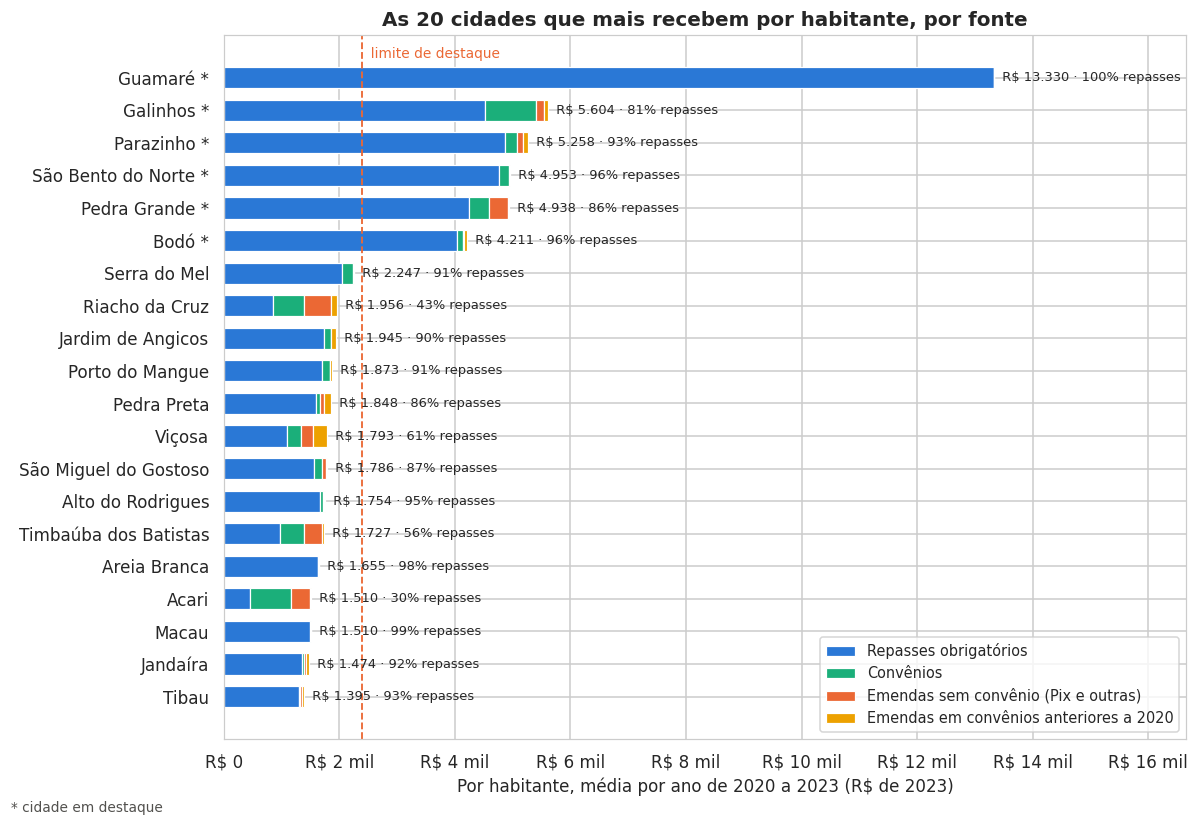

In [10]:
top = uni.sort_values('total_pc_ano', ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7.5))
y = np.arange(len(top))
esquerda = np.zeros(len(top))
for col, nome, cor in FONTES:
    pc = top[col.replace('_valor', '_pc_ano')]
    ax.barh(y, pc, left=esquerda, color=cor, height=0.65, label=nome, edgecolor='white', linewidth=0.8)
    esquerda += pc.values
for yi, (_, linha) in zip(y, top.iterrows()):
    ax.text(linha['total_pc_ano'], yi, f'  R$ {virgula(linha["total_pc_ano"], 0)} · {virgula(linha["rep_pct"], 0)}% repasses',
            va='center', fontsize=8.5)
ax.axvline(LIMITE_TOTAL, color=LARANJA, linestyle='--', linewidth=1.2)
ax.text(LIMITE_TOTAL, len(top) - 0.4, '  limite de destaque', fontsize=9, color=LARANJA)
ax.set_yticks(y)
ax.set_yticklabels([f'{m} *' if d else m for m, d in zip(top['municipio'], top['destaque'])])
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, top['total_pc_ano'].max() * 1.25)
ax.set_xlabel('Por habitante, média por ano de 2020 a 2023 (R$ de 2023)')
ax.set_title('As 20 cidades que mais recebem por habitante, por fonte')
ax.legend(loc='lower right', fontsize=9.5)
fig.text(0.01, 0.005, '* cidade em destaque', fontsize=9, color=TEXTO_2)
plt.tight_layout()
plt.show()

## 5. Ano a ano em cada cidade

Como sugerido pelo professor: o valor de cada ano, por fonte, para ver se a diferença é constante ou se depende de um
ano específico. A linha tracejada é a **mediana do RN** naquele ano, para comparação.

A função `grafico_cidade` desenha qualquer município (por exemplo, as cidades gêmeas do notebook 05):
`grafico_cidade(['Acari', 'Currais Novos'])`.

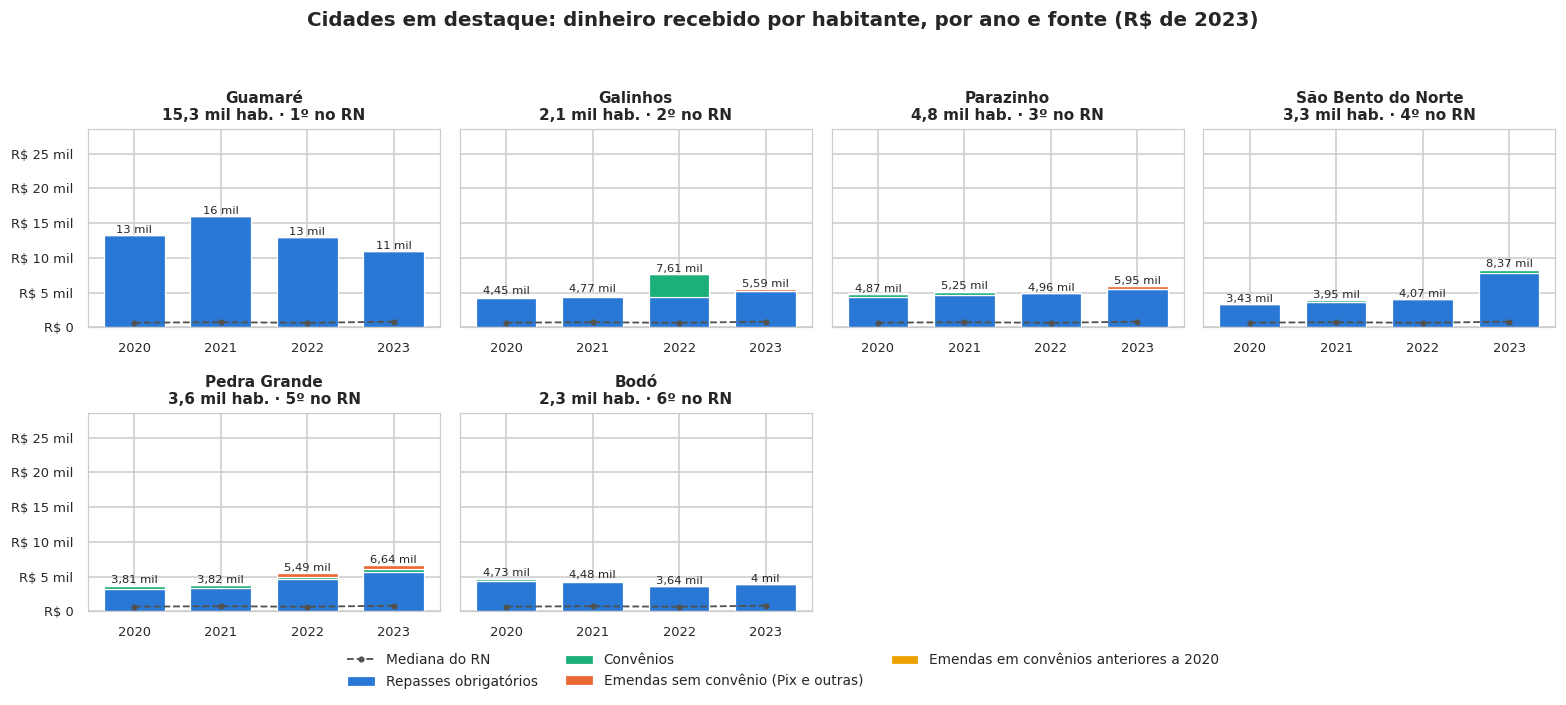

In [11]:
mediana_ano = longo.groupby(['ano', 'cod_ibge'])['valor_pc'].sum().groupby('ano').median()

def grafico_cidade(nomes, por_habitante=True, colunas=4, titulo=None):
    """Barras empilhadas por ano e fonte para cada cidade da lista."""
    nomes = list(nomes)
    faltando = set(nomes) - set(uni['municipio'])
    assert not faltando, f'município não encontrado: {faltando}'
    linhas = int(np.ceil(len(nomes) / colunas))
    fig, axes = plt.subplots(linhas, colunas, figsize=(3.6 * colunas, 3.2 * linhas), sharey=por_habitante, squeeze=False)
    coluna_valor = 'valor_pc' if por_habitante else 'valor_real'
    for ax, nome in zip(axes.flat, nomes):
        dados = (longo[longo['municipio'] == nome].pivot_table(index='ano', columns='fonte', values=coluna_valor,
                                                               aggfunc='sum')
                 .reindex(index=ANOS, columns=[n for _, n, _ in FONTES]).fillna(0))
        fundo = np.zeros(len(ANOS))
        for _, fonte, cor in FONTES:
            ax.bar(ANOS, dados[fonte], bottom=fundo, color=cor, width=0.7, edgecolor='white', linewidth=0.8, label=fonte)
            fundo += dados[fonte].values
        for x, total in zip(ANOS, fundo):
            ax.text(x, total, reais(total).replace('R$ ', ''), ha='center', va='bottom', fontsize=7.5)
        if por_habitante:
            ax.plot(ANOS, mediana_ano.loc[ANOS], color=TEXTO_2, linestyle='--', linewidth=1.2, marker='o', markersize=3,
                    label='Mediana do RN')
        linha = uni[uni['municipio'] == nome].iloc[0]
        ax.set_title(f'{nome}\n{virgula(linha["populacao"] / 1000)} mil hab. · {linha["posicao_total"]}º no RN', fontsize=10)
        ax.set_xticks(ANOS)
        ax.tick_params(labelsize=8.5)
        ax.yaxis.set_major_formatter(FORMATO_REAIS)
    for ax in axes.flat[:len(nomes)]:
        ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    for ax in axes.flat[len(nomes):]:
        ax.axis('off')
    handles, labels = axes.flat[0].get_legend_handles_labels()
    rodape = 0.06 if linhas > 1 else 0.14
    fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0))
    fig.suptitle(titulo or ('Por habitante, por ano (R$ de 2023)' if por_habitante else 'Valor total por ano (R$ de 2023)'),
                 fontsize=13, fontweight='bold')
    plt.tight_layout(rect=(0, rodape, 1, 0.95))
    plt.show()

destaques = uni[uni['destaque']].sort_values('total_pc_ano', ascending=False)['municipio'].tolist()
grafico_cidade(destaques, titulo='Cidades em destaque: dinheiro recebido por habitante, por ano e fonte (R$ de 2023)')

**Perto do limite:** as cidades que saíram da lista e as que ficaram logo abaixo dele.

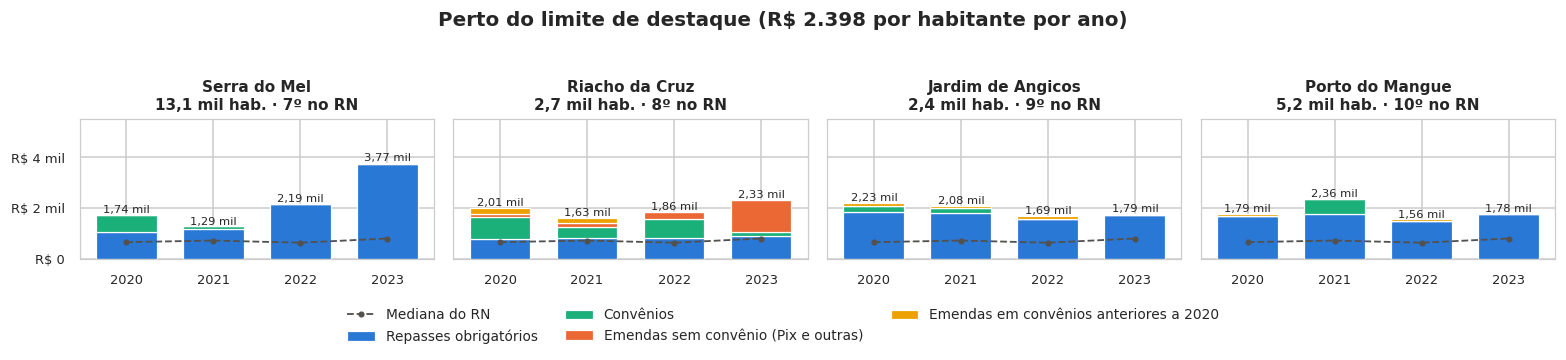

In [12]:
vizinhas = sairam + uni[~uni['destaque'] & ~uni['municipio'].isin(sairam)].nlargest(3, 'total_pc_ano')['municipio'].tolist()
grafico_cidade(vizinhas, titulo=f'Perto do limite de destaque (R$ {virgula(LIMITE_TOTAL, 0)} por habitante por ano)')

As cidades em destaque recebem tanto que a escala esconde as demais. Para comparar com cidades que se destacam por
convênios e emendas (e não por repasses), o mesmo gráfico com as que mais subiram no ranking:

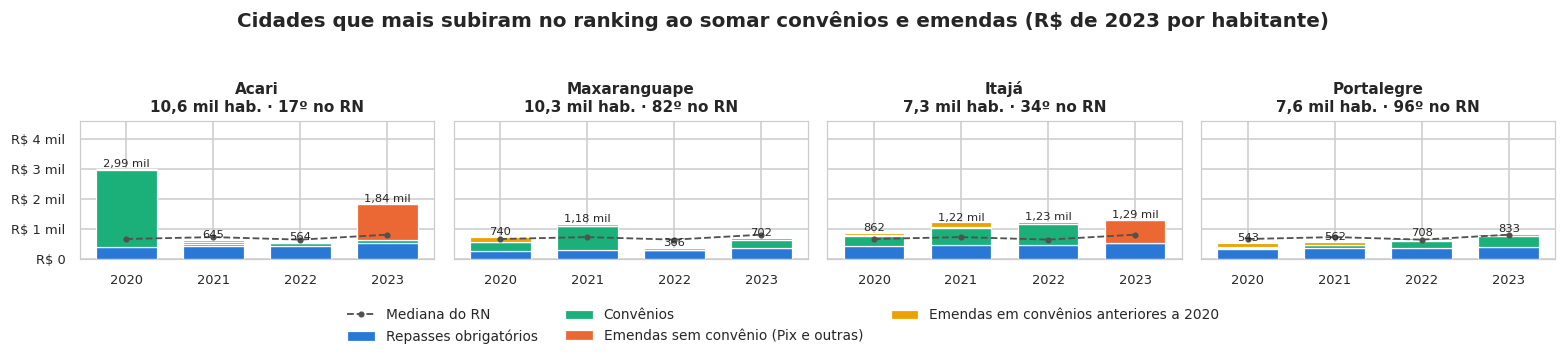

In [13]:
grafico_cidade(maiores_subidas['municipio'].head(4).tolist(),
               titulo='Cidades que mais subiram no ranking ao somar convênios e emendas (R$ de 2023 por habitante)')

In [14]:
# Variação entre anos: quanto o total por habitante oscila em cada cidade em destaque
variacao = (longo[longo['municipio'].isin(destaques)].groupby(['municipio', 'ano'])['valor_pc'].sum().unstack()
            .reindex(destaques))
variacao['Menor ano ÷ maior ano'] = variacao[ANOS].min(axis=1) / variacao[ANOS].max(axis=1)
variacao['Vezes a mediana (menor ano)'] = (variacao[ANOS] / mediana_ano.loc[ANOS].values).min(axis=1)
variacao.round(1)

ano,2020,2021,2022,2023,Menor ano ÷ maior ano,Vezes a mediana (menor ano)
municipio,,,,,,
Guamaré,"13,342.2","16,086.2","12,949.9","10,943.0",0.7,13.4
Galinhos,"4,447.3","4,771.1","7,609.6","5,586.3",0.6,6.5
Parazinho,"4,871.9","5,254.3","4,958.6","5,947.1",0.8,7.1
São Bento do Norte,"3,428.8","3,946.0","4,065.4","8,370.8",0.4,5.1
Pedra Grande,"3,811.9","3,816.0","5,487.7","6,638.4",0.6,5.2
Bodó,"4,732.1","4,477.9","3,636.4","3,997.6",0.8,4.9


## 6. Arquivos finais

In [15]:
uni['fonte_principal'] = uni[[c for c, _, _ in FONTES]].idxmax(axis=1).map({c: n for c, n, _ in FONTES})
final = uni[['cod_ibge', 'municipio', 'mesorregiao', 'regiao_intermediaria', 'populacao', 'porte', 'pib_per_capita',
             'pct_baixa_renda', 'rep_valor', 'conv_valor', 'emendas_sem_conv_valor', 'emendas_conv_anterior_valor',
             'total_valor', 'rep_pc_ano', 'conv_pc_ano', 'emendas_sem_conv_pc_ano', 'emendas_conv_anterior_pc_ano',
             'total_pc_ano', 'rep_pct', 'conv_pct', 'emendas_sem_conv_pct', 'emendas_conv_anterior_pct',
             'fonte_principal', 'posicao_repasses', 'posicao_total', 'vezes_mediana', 'anos_acima', 'destaque',
             'destaque_so_repasses']].sort_values('cod_ibge')
final.to_csv('resultado_final/saida/04_base_unificada_2020_2023.csv', index=False)

longo_saida = longo[['cod_ibge', 'municipio', 'ano', 'fonte', 'valor_real', 'valor_pc']].sort_values(['cod_ibge', 'ano', 'fonte'])
longo_saida.to_csv('resultado_final/saida/04_base_unificada_municipio_ano.csv', index=False)

lista = final[final['destaque']].sort_values('posicao_total').copy()
lista['motivo'] = [f'Recebe {virgula(v)} vezes a mediana do RN por habitante; {virgula(p, 0)}% vem de {f.lower()}; '
                   f'acima do limite em {a} de 4 anos' for v, p, f, a in
                   zip(lista['vezes_mediana'], lista[['rep_pct', 'conv_pct', 'emendas_sem_conv_pct',
                                                      'emendas_conv_anterior_pct']].max(axis=1),
                       lista['fonte_principal'], lista['anos_acima'])]
lista[['cod_ibge', 'municipio', 'populacao', 'total_pc_ano', 'vezes_mediana', 'fonte_principal', 'anos_acima',
       'destaque_so_repasses', 'motivo']].to_csv('resultado_final/saida/04_cidades_destaque.csv', index=False)

assert len(final) == 167 and abs(final['total_valor'].sum() - longo_saida['valor_real'].sum()) < 1
print(f'04_base_unificada_2020_2023.csv: 167 municípios | 04_base_unificada_municipio_ano.csv: {len(longo_saida):,} linhas | '
      f'04_cidades_destaque.csv: {len(lista)} cidades'.replace(',', '.'))
lista[['municipio', 'motivo']]

04_base_unificada_2020_2023.csv: 167 municípios | 04_base_unificada_municipio_ano.csv: 2.009 linhas | 04_cidades_destaque.csv: 6 cidades


,municipio,motivo
49,Guamaré,"Recebe 18,0 vezes a mediana do RN por habitante; 100% vem de repas..."
45,Galinhos,"Recebe 7,6 vezes a mediana do RN por habitante; 81% vem de repasse..."
95,Parazinho,"Recebe 7,1 vezes a mediana do RN por habitante; 93% vem de repasse..."
126,São Bento do Norte,"Recebe 6,7 vezes a mediana do RN por habitante; 96% vem de repasse..."
103,Pedra Grande,"Recebe 6,7 vezes a mediana do RN por habitante; 86% vem de repasse..."
17,Bodó,"Recebe 5,7 vezes a mediana do RN por habitante; 96% vem de repasse..."


**Dicionário do `04_base_unificada_2020_2023.csv`** (valores somados de 2020 a 2023, em R\$ de 2023):

| Coluna | O que é |
|---|---|
| `rep_valor` | Repasses obrigatórios (notebook 01) |
| `conv_valor` | Convênios federais e estaduais iniciados em 2020–2023 (notebook 02) |
| `emendas_sem_conv_valor` | Emendas pagas sem convênio: Pix e outros pagamentos diretos (notebook 03) |
| `emendas_conv_anterior_valor` | Emendas pagas em 2020–2023 em convênios iniciados antes de 2020 (seção 2) |
| `total_valor` | Soma das quatro |
| `*_pc_ano` | Valor ÷ população ÷ 4 anos: **R\$ por habitante por ano** |
| `*_pct` | Parte de cada fonte no total do município (%) |
| `fonte_principal` | A fonte com o maior valor no município |
| `posicao_repasses`, `posicao_total` | Posição no ranking por habitante só com repasses e com todas as fontes |
| `vezes_mediana` | Total por habitante ÷ mediana do RN |
| `anos_acima` | Em quantos dos 4 anos o município ficou acima do limite de destaque |
| `destaque`, `destaque_so_repasses` | Se o município é destaque com todas as fontes e só com repasses |

## 7. Conclusões e cuidados

**O que os dados mostram (2020–2023, em R\$ de 2023):**

1. **R\$ 10,4 bilhões chegaram às prefeituras do RN** pelas quatro fontes. Os repasses obrigatórios são 85% desse
   total; convênios, 9%; emendas, 6% (3,1% sem convênio e 2,8% em convênios antigos).
2. **A conciliação evitou dois erros:**
   - **perder R\$ 295 milhões** de emendas pagas em 2020–2023 em convênios que começaram antes de 2020. Elas não estavam
     nem no 02 (fora do recorte) nem no total sem convênio do 03;
   - **contar duas vezes R\$ 226 milhões** de emendas pagas em convênios que o 02 já conta.
3. **As cidades em destaque praticamente não mudam:** Guamaré, Galinhos, Parazinho, São Bento do Norte, Pedra Grande e
   Bodó continuam acima do limite (R\$ 2.398 por habitante por ano, 3,2 vezes a mediana), **nos 4 anos**. Em todas
   elas, 81% a 100% do dinheiro vem de repasses obrigatórios. Convênios e emendas não mudam o padrão porque são pequenos
   perto do ICMS dessas cidades.
4. **Serra do Mel sai da lista:** continua em 7º lugar, mas o limite sobe quando se somam as outras fontes. Ela só passou
   do limite em 2023, quando os repasses quase dobraram. Isso sugere que a cidade está **entrando** no grupo, e não
   que já pertença a ele de forma estável.
5. **Nenhuma cidade entra na lista**, mas o ranking muda abaixo do topo. A correlação entre o ranking só com repasses e
   o ranking com tudo é alta (0,94). Mesmo assim, cidades com muita emenda e convênio sobem muito: Riacho da Cruz vai
   de 36º para 8º, Acari de 105º para 17º e Itajá de 97º para 34º. Nessas cidades, menos da metade do dinheiro vem de
   repasses.
6. **Os destaques são estáveis no tempo:** mesmo no pior ano, cada um recebeu pelo menos 4,9 vezes a mediana do RN.
   Há oscilações (Galinhos em 2022, por um convênio grande; São Bento do Norte em 2023, por aumento do ICMS), mas o
   destaque não depende de um ano específico.

**Cuidados:**

- **Convênios contam no ano de início**, com o valor liberado até hoje; repasses e emendas, no ano do recebimento. Por
  isso os gráficos ano a ano dos convênios mostram quando o convênio começou, e não quando o dinheiro chegou.
- **A saúde fundo a fundo não entra** (decisão do grupo): de 2020 a 2023 o Portal não informa o município. Os totais de
  emendas são, portanto, um piso.
- **Convênios estaduais** usam o valor combinado, porque o sistema do Estado não informa o valor pago.
- **Emendas estaduais** (deputados estaduais) não estão na base, porque só existem em PDF sem município padronizado.

**Próximo passo (notebook 05):** escolher a cidade gêmea de cada cidade em destaque de `04_cidades_destaque.csv`, ou
seja, um município parecido em população, região e pobreza, mas que recebe o valor normal do RN.